# 🎯 Notebook 06.2: K-Means Deep Dive
## Phase 1: The WCSS Elbow Method
First, we will use the standard **Elbow Method (WCSS)** to find the optimal number of clusters (`K`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

X_scaled = pd.read_csv('../../data/processed/X_cluster_scaled.csv')
X_raw = pd.read_csv('../../data/processed/X_cluster_raw.csv')
y_price = pd.read_csv('../../data/processed/y_cluster_price.csv').squeeze()

### 1. WCSS (Inertia) Plot
We test `K` from 2 to 8 and plot the variance.

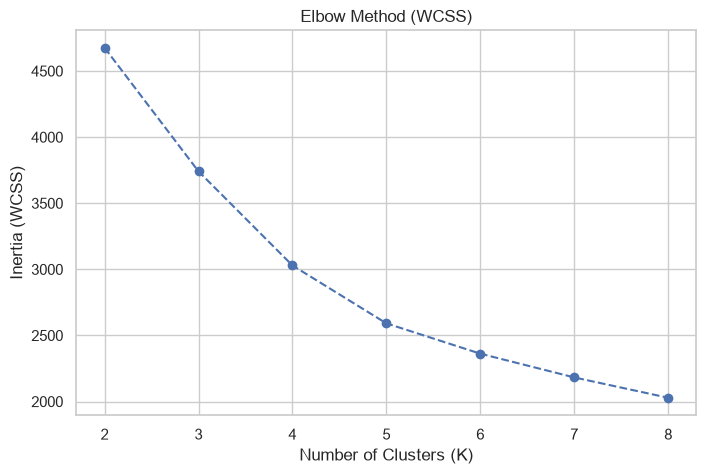

In [2]:
wcss = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method (WCSS)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.show()

### 2. Testing K=4
Looking at the graph above, the variance drops heavily until `K=4`, where it begins to smooth out. Based purely on the Elbow Method, `K=4` seems like the logical choice. Let's fit the model and look at the physical averages (centroids) of the 4 clusters.

In [3]:
kmeans4 = KMeans(n_clusters=4, random_state=42, n_init=10)
X_raw['Cluster_K4'] = kmeans4.fit_predict(X_scaled)
X_raw['SalePrice'] = y_price

centroids4 = X_raw.groupby('Cluster_K4').mean().round(1).sort_values('SalePrice')
display(centroids4)

,TotalSF,OverallQual,YearBuilt,LotArea,GarageCars,SalePrice
Cluster_K4,,,,,,
1,2051.7,5.1,1944.4,8799.5,1.1,125003.7
2,2560.4,6.3,1985.8,9989.0,2.0,180605.0
3,3628.0,6.2,1964.8,163513.5,2.0,295737.5
0,3716.2,8.0,1997.0,13244.6,2.7,304642.9


### 🚨 The Business Problem with K=4
When we look at the data, the first 3 tiers make sense (Starter, Mid, Luxury). But look at the final cluster: **The average Lot Area is 163,513 sq ft!**

By choosing `K=4`, the algorithm isolated rural farms and massive acreage properties. While this is mathematically valid, it breaks our business logic. We cannot build a standard residential Renovation ROI tool if the data is skewed by farms. 

**We need a more advanced mathematical metric to see if K=4 is actually necessary, or if K=3 is a cleaner fit.**

### 3. Advanced Research: The Silhouette Score
Because the Elbow Method was ambiguous, we researched a more advanced metric: The **Silhouette Score**. 
Unlike WCSS (which just measures variance), the Silhouette Score measures how *cleanly separated* the boundaries between the clusters are. It scores from -1 to +1.

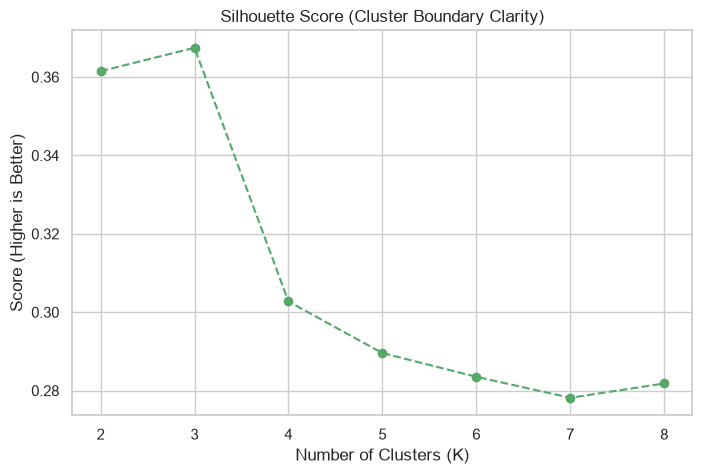

In [4]:
sil_scores = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(k_range, sil_scores, marker='o', linestyle='--', color='g')
plt.title('Silhouette Score (Cluster Boundary Clarity)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Score (Higher is Better)')
plt.show()

### 4. The Mathematical Pivot to K=3
The Silhouette Score reveals that `K=3` is the absolute mathematical peak (~0.367). 
When we pushed it to `K=4`, the boundary clarity plummeted to ~0.30. This mathematically proves that forcing the algorithm to find farms (K=4) actually blurred the boundaries of the normal residential homes. 

We will finalize our model at **`K=3`**.

In [5]:
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
X_raw['Market_Tier'] = kmeans3.fit_predict(X_scaled)

centroids3 = X_raw.groupby('Market_Tier').mean().round(1).sort_values('SalePrice')
tier_mapping = {
    centroids3.index[0]: 'Starter Home',
    centroids3.index[1]: 'Mid-Market Suburban',
    centroids3.index[2]: 'Luxury Estate'
}
centroids3.index = tier_mapping.values()
X_raw['Market_Tier'] = X_raw['Market_Tier'].map(tier_mapping)
display(centroids3)

,TotalSF,OverallQual,YearBuilt,LotArea,GarageCars,Cluster_K4,SalePrice
Starter Home,2113.2,5.2,1950.2,9124.5,1.3,1.2,131802.6
Mid-Market Suburban,3053.9,7.1,1994.2,11152.1,2.3,1.3,233604.1
Luxury Estate,3628.0,6.2,1964.8,163513.5,2.0,3.0,295737.5


### 5. Final Visualization (PCA Projection)
Because we trained the algorithm on 5 dimensions (Size, Quality, Age, Lot, Garage), we cannot easily plot it on a 2-dimensional screen without the dots overlapping. 
To solve this, we use **PCA (Principal Component Analysis)**. PCA mathematically squashes all 5 dimensions down into 2 'Principal Components' while preserving the variance. This allows us to see the 3 tiers as beautifully distinct clusters.

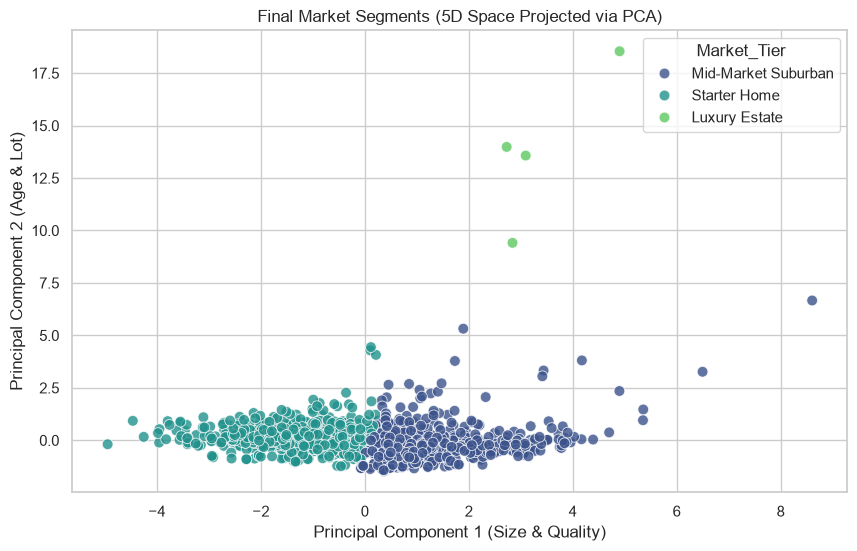

Model mathematically justified, PCA visualized, and saved!


In [6]:
from sklearn.decomposition import PCA

# Compress 5D scaled data into 2D for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
X_raw['PCA1'] = X_pca[:, 0]
X_raw['PCA2'] = X_pca[:, 1]

# Plot the 3 distinct blobs
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=X_raw, 
    x='PCA1', 
    y='PCA2', 
    hue='Market_Tier', 
    palette='viridis', 
    alpha=0.8,
    s=60
)
plt.title('Final Market Segments (5D Space Projected via PCA)')
plt.xlabel('Principal Component 1 (Size & Quality)')
plt.ylabel('Principal Component 2 (Age & Lot)')
plt.show()

joblib.dump(kmeans3, '../../models/kmeans_tier_model.pkl')
joblib.dump(tier_mapping, '../../models/tier_mapping.pkl')
print("Model mathematically justified, PCA visualized, and saved!")